# Budapest Airbnb: what explains price and demand when ratings are almost all the same?

## Project question

Most Airbnb listings in Budapest with enough reviews sit in a narrow band near the top of the rating scale, so a rating barely helps a guest choose between them. If quality looks the same, what actually explains the differences in price and demand: location, size of the apartment, or who the host is (a private host or a professional operator)?

## Data

Inside Airbnb, Budapest, detailed listings file (snapshot labelled 21 September 2026): 11,240 listings, 4,540 hosts. License: CC BY 4.0. Source: insideairbnb.com

## Approach

1. Describe the market and how concentrated it is among hosts.
2. Show how compressed ratings are, and when a rating is just noise (too few reviews).
3. Explain price and demand with regression, controlling for size, district and host type.
4. Check that the conclusions survive different data-cleaning choices.

## Data dictionary

Based on the official Inside Airbnb Data Dictionary (listings.csv detailed, v4.7). Columns are split into those described in the dictionary and those that are not.

### Documented in the Data Dictionary

| Column | Meaning (per dictionary) | How it is used here |
|---|---|---|
| `id` | Unique listing identifier | Key |
| `host_id` | Unique host identifier | Group listings by host |
| `room_type` | Entire home/apt, Private room, Shared room or Hotel room | Price and demand analysis uses entire homes only |
| `neighbourhood_cleansed` | District assigned from latitude/longitude using public shapefiles (coordinates are anonymised, so borders are approximate) | Location control |
| `accommodates`, `bedrooms` | Maximum capacity and number of bedrooms | Size controls |
| `price` | Daily price in local currency (HUF); the "$" sign is an export artefact | Price outcome (see caveats below) |
| `minimum_nights` | Minimum stay; calendar rules may differ | Exclude stays of 28+ nights (long-term rentals) |
| `availability_365` | Days available in the next 365 days; a day can be unavailable because it is booked or blocked by the host | Not used as a demand measure |
| `number_of_reviews` | Total number of reviews | Rating reliability, listing maturity |
| `number_of_reviews_ltm` | Reviews in the last 12 months | Main demand proxy |
| `calculated_host_listings_count` (also `_entire_homes`, `_private_rooms`) | Number of listings the host has in this scrape, within the city only | Host size: 1 / 2-4 / 5-19 / 20+ |
| `source` | "neighbourhood search" or "previous scrape" (listing seen in a scrape in the last 65 days and confirmed still available). In this file only "previous scrape" is filled (1,470 listings) | Data-quality flag |

### Not documented in the Data Dictionary (relying on our own checks)

| Column | What we know from checks | Caveat |
|---|---|---|
| `review_scores_rating` and six sub-scores (`accuracy`, `cleanliness`, `checkin`, `communication`, `location`, `value`) | Listed in the dictionary without a description. Values range from 1 to 5 in this file | Scale and calculation are not documented |
| `host_is_superhost` | Listed without a description. Values t / f | Definition not documented |
| `estimated_occupancy_l365d` | Not in the dictionary. Correlates 0.90 with reviews in the last 12 months; 16.1% of listings have 0 (the same share has no reviews in the last year); 20.3% sit at exactly 255 nights (70% of 365) | Behaviour is consistent with Inside Airbnb's occupancy model described on its Data Assumptions page (reviews-based, capped at 70%), but this link is our inference. It is an estimate, not real bookings, and is not independent of ratings |
| `estimated_revenue_l365d` | Not in the dictionary. Roughly equals occupancy x price in about 90% of rows | Derived from the two columns above, so not an independent outcome |
| `price_quote_*` columns | Not in the dictionary. `price` is a one-night quote for a specific check-in date (mostly September-October 2026, some up to September 2027); about 16% of quotes include a discount | Price is not an annual average; we control for the quote month |
| `hosts_time_as_host_years` and similar | Not in the dictionary | Not used |

## Hypotheses

Written before running any models. Hypotheses H0, H1, H3, H4 and H5 were partly visible in early descriptive checks, so they mainly describe the market. H2 and H6-H9 are real tests. The "Result" column is filled in after the analysis.

| # | Hypothesis | Sample | Refuted if... | Result |
|---|---|---|---|---|
| H0 | Missing prices are not random: most of them come from listings with `source = previous scrape`. | All listings | Missing prices are spread evenly across both sources | Supported: 94% of missing prices (1,054 of 1,123) are previous-scrape listings; 71.7% of those lack a price vs 0.7% of search listings. |
| H1 | Among listings with 10+ reviews, ratings are genuinely compressed near the top (80% between about 4.53 and 4.96). With few reviews, a rating is mostly noise. | All listings with a rating | A wide spread persists even at 30+ reviews | Supported: std falls from 0.81 (1-4 reviews) to 0.14 (100+); share of exact 5.0 falls from 55.3% to 0.8%; at 10+ reviews, 80% of listings lie between 4.53 and 4.96. |
| H2 | With size, district and quote month held equal, rating and superhost status are weakly related to price and demand (rating effect measured across its 10th-90th percentile range). | Entire homes | A clear, sizeable rating effect after controls | Not supported as stated: rating (p10 -> p90) goes with +21.6% price and +45.2% reviews. The superhost effect is not robust for price and not interpretable for demand (see note H2 and D25). |
| H3 | Cleanliness differs most between listings and communication least. Sub-scores relate differently to price and demand (value is judged relative to price). | Listings with 10+ reviews | Equal spread and equal relationships | Partly supported: sub-score spread differs (cleanliness largest, std 0.21; communication smallest, 0.13). The relationship of each sub-score with price and demand was not tested. |
| H4 | Hosts are concentrated: 7.6% of hosts hold 47.6% of listings, and the pattern differs by district. | All listings | An even distribution across districts | Supported: 7.6% of hosts (344) hold 47.6% of listings; the share held by 5+ hosts ranges from 25.0% (II. kerület) to 56.4% (VIII. kerület) across the 12 districts with 100+ listings. |
| H5 | Large operators have lower ratings and fewer superhosts, and this is not explained by district and size alone. | Entire homes, 10+ reviews | The gap disappears once controls are added | Supported: vs hosts with one entire home, 20+ hosts have 0.146 lower rating points (95% CI -0.157 to -0.136) and 33.6 pp fewer superhosts after controlling for bedrooms, district and number of reviews. The raw gaps (-0.166 points, -38.0 pp) shrink by only about 12%. |
| H6 | Composition effect: average price looks the same across host types, but within segments (bedrooms x central/non-central district) it differs, possibly with a reversed sign (Simpson's paradox). | Entire homes | The same difference on average and within segments | Partly supported (composition effect): median prices differ by <3% across host groups (R2 = 0.001). At equal size and district, 5-19 hosts charge 3.7-5.5% less in all 8 robustness variants; for 20+ hosts there is no robust gap (-2.2%, CI includes 0). Holding rating and superhost equal, 20+ hosts charge +3.5% to +7.0% more in 7 of 8 variants, because large operators have lower ratings. See robustness notes. |
| H7 | Size and district explain most of the price variation. Rating and host type add little. | Entire homes | Rating or host type add a comparable share of explained variance | Partly supported: bedrooms alone explain R2 = 0.302, district alone 0.023, rating + superhost 0.025, host group 0.001 (full model 0.357; without host group 0.355). |
| H8 | With size, district and price held equal, demand (reviews in the last 12 months) differs between operators and private hosts (initially expected to be higher for operators). | Entire homes | No difference after controls | Partly supported, opposite direction to the initial expectation: raw demand is similar across host groups, and the 20+ gap is not clear until price is held equal (-5.8% [-12.4, +1.4] at step 3). With price, quote month and minimum nights held equal, 20+ hosts get 16.3% fewer reviews (CI -21.9 to -10.3), 5-19 hosts 10.3% fewer, 2-4 no difference. Poisson (-18.7%) and estimated occupancy (-14.8 nights) agree. Caveat: price may be a mediator. |
| H9 | With size and district held equal, a higher price goes with lower demand (exploratory: price is a single quote that may include a discount). | Entire homes | No relationship, or a positive one | Supported: +10% price goes with -7.6% reviews (CI -8.1 to -7.0); Poisson -5.5%. Association only: price is a single quote and may include a discount.|

**Note H2 (details)**

- **Rating and price (stage 4):** at equal size, district and quote month, rating p10 -> p90 goes with +21.6% price (CI +18.2 to +25.2), although it adds only about 0.02 to R2.
- **Rating and demand (stage 5):** the same rating range goes with +45.2% reviews in the last 12 months (CI +35.6 to +55.4). Rating and reviews come from the same reviews, so this is co-movement, not an effect.
- **Superhost and demand:** +79.5% reviews, but the badge criteria include completed stays and rating, so the link is partly mechanical (see D25).
- **Superhost and price:** not robust. The difference is -1.2% (no controls), +2.5% (size, district, quote month), +3.0% (+ host group) and -4.1% (+ rating), and it is concentrated among single-listing hosts (-13.4%).
- **Robustness (stage 6):** the sign of the rating-price link is stable in all 8 variants, but its size ranges from +8% to +28% depending on the sample (+8% when ratings based on few reviews are included).

## Decision log

Every data-cleaning or modelling choice is recorded here: what was decided, why, and the effect (rows removed or numbers changed). Entries are numbered D1, D2, ... so that findings and the README can refer to them.

**Format:** `D# [status] What / Why / Effect`
**Status:** `planned` (decided in advance, not yet run), `done` (run and confirmed), `changed` (revised after seeing the data), `open` (still to be decided).

If my numbers differ from the reference ones below, set the status to `changed` and correct the Effect.

---

**D1 [done]** What: Price and demand analysis uses entire homes only (`room_type = Entire home/apt`). Why: Room type strongly changes price and guest behaviour, and private rooms are only about 9% of listings. Effect: 11,240 -> 10,147 rows.

**D2 [done]** What: Host size groups (1 / 2-4 / 5-19 / 20+) use `calculated_host_listings_count_entire_homes` for price and demand, and the total `calculated_host_listings_count` for market structure. The total count is also used as a robustness check. Why: Avoids labelling a host as private just because they have one apartment and many rooms. Counts cover Budapest only. Effect: none on rows.

**D3 [done]** What: The main demand measure is `number_of_reviews_ltm` (documented). `estimated_occupancy_l365d` is secondary. `availability_365` is not used as demand. Why: Estimated occupancy is not in the Data Dictionary, depends on reviews and is capped at 255 nights. Availability can be blocked by the host. Effect: none on rows.

**D4 [done]** What: Rating analysis uses only listings with 10+ reviews. Why: With 1-4 reviews the rating spread is huge (std 0.81) and 55% of ratings are exactly 5.0. With 100+ reviews std is 0.14. Effect: about 7,200 entire-home listings remain in the rating analysis.

**D5 [done]** What: Listings with `source = previous scrape` are flagged, not removed. A robustness check repeats the main results without them. Why: There are 1,470 of them, 71.7% have no price, so missing prices are not random. Effect: 243 such listings remain in the price sample.

**D6 [done]** What: Listings without a price are excluded from price and demand analysis. Why: Price is a required variable. Effect: 10,147 -> 9,146.

**D7 [done]** What: Listings with `minimum_nights >= 28` are excluded. Why: Long-term rentals behave differently and the dictionary notes that calendar rules may differ. Effect: 9,146 -> 8,946.

**D8 [done]** What: Prices above the 99th percentile (about 475,623 HUF) are excluded. Why: Extreme outliers (the maximum is above 14 million HUF). Effect: 8,946 -> 8,856.

**D9 [done]** What: Regressions use log price. Tables report medians. Why: Price is strongly right-skewed. Effect: none on rows.

**D10 [done]** What: Bedrooms are capped at 4 (4 means 4+). Studios (0 bedrooms) are kept as their own group. Why: Few listings have 5+ bedrooms. Effect: none on rows.

**D11 [done]** What: Do not exclude listings that look inactive (`availability_365 = 0` and `number_of_reviews_ltm = 0`). Why: The main sample has no listings with `availability_365 = 0` (likely because a price quote requires open dates). 872 listings have no reviews in the last 12 months, but they are open for booking, so there is no evidence they are inactive. They may be new or simply have little demand, and dropping them would hide the low-demand end of the market. Effect: none on rows (0 removed, 8,856 remain).

**D12 [done]** What: Districts with fewer than 100 listings in the main sample are grouped as "Other" in regressions. Why: Tiny districts give unstable coefficients. Effect: 11 named districts plus "Other" (190 listings in the rated sample).

**D13 [done]** What: Central districts = V, VI, VII kerület (used only for the composition test H6). Why: Largest and most tourist-oriented districts by listing count, simple binary split. Effect: none on rows.ё

**D14 [done]** What: District charts show only districts with 100+ listings (12 of 23). Why: Shares in tiny districts are noisy. Effect: 257 listings in 11 districts are not shown; totals use all 11,240 listings.

**D15 [done]** What: H1 and H3 use all listings with a rating (any room type); H5 uses the rated entire-home sample. Why: H1 and H3 describe how ratings behave overall; H5 compares host groups on the same sample as the price analysis. Effect: 8,454 listings with 10+ reviews overall vs 7,207 in the rated sample.

**D16 [done]** What: Price models run on the rated sample (7,207), with models 1-3 repeated on the main sample (8,856) as a robustness check. Why: Models 4-5 need a reliable rating, and all steps must use identical rows to be comparable. Effect: 1,649 fewer rows than main; direction of effects unchanged on main.

**D17 [done]** What: Quote months grouped as 2026-09, 2026-10, 2026-11, later (Dec 2026 - Sep 2027). Why: Each later month has fewer than 135 listings. Effect: 441 listings in "later" (298 in the rated sample).

**D18 [done]** What: Segment tables hide cells with fewer than 30 listings; the 4+ bedroom row is not interpreted. Why: Cells of 34-85 listings give swings of tens of percent. Effect: no rows removed.

**D19 [done]** What: Price effects are reported as exp(b) - 1 (percent) with 95% confidence intervals from robust (HC3) standard errors. Why: Log price makes coefficients proportional; HC3 does not assume equal variance across groups. Effect: none on rows.

**D20 [done]** What: Demand models use the main sample (8,856), not rated; total number of reviews is not used as a control. Why: Selecting on 10+ total reviews would select on the outcome (zero-review listings: 9.8% in main vs 3.3% in rated). Effect: none on rows.

**D21 [done]** What: Demand outcome is log(1 + reviews in the last 12 months); Poisson on counts as robustness. Why: Zeros must stay in the data; Poisson does not need a log transform. Effect: none on rows.

**D22 [done]** What: Rating and superhost enter demand models only in separate models (rated and main-with-rating), interpreted as associations. Why: They come from the same reviews as the outcome. Effect: 7,207 and 8,502 rows.

**D23 [done]** What: Occupancy models are run with and without listings at the 255-night cap. Why: The cap is censoring. Effect: 2,035 listings (23.0%) at the cap, 6,821 remain without it.

**D24 [done]** What: Zero-review listings (872 = 354 never reviewed + 518 dormant) are kept in all demand models; B1 is only a descriptive first look. Why: They are genuine low demand (see D11). Effect: none on rows.

**D25 [done]** What: No causal claim is made about the Superhost badge. Only descriptive diagnostics (share by rating and by reviews) and price differences across four specifications. Why: Badge criteria include stays and rating, which overlap with demand and reviews; the badge is account-level while rating and reviews are listing-level. Effect: none on rows.

**D26 [done]** What: Main conclusions were re-estimated in 8 variants (without previous-scrape listings; host group by total count; rating sample without the 10-review rule and only 4.7+; no price cut and a 95th-percentile cut; entire homes + private rooms; occupancy outcome with and without the 255 cap). Why: To see which conclusions depend on cleaning and definition choices. Rule: a conclusion counts as robust if its sign is the same in all variants and it is significant in all or nearly all. Effect: none on the baseline; the 20+ price gap at equal size and district is not robust.

---

**New decisions:**

## Ideas backlog

Ideas that came up during the analysis. They are NOT part of the pre-registered hypotheses (H0-H9) and are exploratory.

**B1. Listings with no reviews in the last 12 months (872 of 8,856 in the main sample)**
Where to look at this: stage 5 (demand).
First split: (a) never reviewed (`number_of_reviews = 0`) vs (b) reviewed earlier but not in the last 12 months (`number_of_reviews > 0`, `number_of_reviews_ltm = 0`). These are likely different populations: new or never-booked listings versus dormant ones.
What to compare against listings with recent reviews: host group (`host_group`), district, price relative to similar listings (same bedrooms and district), `minimum_nights`, `last_review` date, share of "previous scrape" listings.
Caveat: zero reviews does not mean zero bookings, and `estimated_occupancy_l365d` is 0 for these listings by construction.

**Draft hypothesis H10 (exploratory, added after seeing the data):** Listings without reviews in the last 12 months are not random: they are over-represented in certain host groups or price levels, compared with similar listings that do have reviews.
Refuted if: their share is about the same across host groups, districts and price levels after controlling for size.
Result: Supported in a first descriptive look: listings without reviews in the last 12 months (872) are priced 25-29% above similar listings, are rarely superhost (12-13% vs 48%) and are over-represented among 1-listing hosts (34% vs 28.5%). No formal test yet.

## Stage 1. Loading and cleaning

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("..") / "data" / "budapest_listings.csv.gz"
df = pd.read_csv(DATA, low_memory=False)

In [3]:
pd.crosstab(df["source"].fillna("search"), df["price"].isna())

src = df["source"].fillna("search")
print(pd.crosstab(src, df["price"].isna(), margins=True))
print(pd.crosstab(src, df["price"].isna(), normalize="index").round(3))

price            False  True    All
source                             
previous scrape    416  1054   1470
search            9701    69   9770
All              10117  1123  11240
price            False  True 
source                       
previous scrape  0.283  0.717
search           0.993  0.007


In [4]:
# price: strip everything except digits and the dot, then convert
df["price_num"] = pd.to_numeric(
    df["price"].astype(str).str.replace(r"[^0-9.]", "", regex=True),
    errors="coerce",
)
df["log_price"] = np.log(df["price_num"])

# host size groups: by entire-home count (main) and by total count (robustness)
bins, labels = [0, 1, 4, 19, np.inf], ["1", "2-4", "5-19", "20+"]
df["host_group"] = pd.cut(df["calculated_host_listings_count_entire_homes"], bins=bins, labels=labels)
df["host_group_total"] = pd.cut(df["calculated_host_listings_count"], bins=bins, labels=labels)

df["bedrooms_cap"] = df["bedrooms"].clip(upper=4)
df["quote_month"] = pd.to_datetime(df["price_quote_checkin_date"]).dt.strftime("%Y-%m")
df["superhost"] = (df["host_is_superhost"] == "t").astype(int)
df["prev_scrape"] = (df["source"] == "previous scrape").astype(int)
df["center"] = df["neighbourhood_cleansed"].isin(["V. kerület", "VI. kerület", "VII. kerület"])

new_cols = ["price_num", "log_price", "host_group", "host_group_total", "bedrooms_cap",
            "quote_month", "superhost", "prev_scrape", "center"]
print(df[new_cols].isna().sum())
df[new_cols].head()

price_num           1123
log_price           1123
host_group           469
host_group_total       0
bedrooms_cap           0
quote_month         1046
superhost              0
prev_scrape            0
center                 0
dtype: int64


,price_num,log_price,host_group,host_group_total,bedrooms_cap,quote_month,superhost,prev_scrape,center
0,35109.0,10.466213,2-4,2-4,2,2026-10,1,0,False
1,44889.0,10.711948,2-4,2-4,2,2026-09,1,0,False
2,97793.0,11.490608,5-19,5-19,4,2026-09,1,0,True
3,42217.0,10.650578,5-19,5-19,3,2026-10,1,0,True
4,35833.0,10.486625,5-19,5-19,2,2026-09,1,0,True


In [5]:
steps = []
d = df.copy()
steps.append(("All listings", len(d)))

d = d[d["room_type"] == "Entire home/apt"]
steps.append(("Entire homes only", len(d)))

d = d[d["price_num"].notna()]
steps.append(("Price present", len(d)))

d = d[d["minimum_nights"] < 28]
steps.append(("Minimum nights < 28", len(d)))

p99 = d["price_num"].quantile(0.99)
d = d[d["price_num"] <= p99]
steps.append((f"Price <= 99th percentile ({p99:,.0f} HUF)", len(d)))

funnel = pd.DataFrame(steps, columns=["step", "rows_left"])
funnel["removed"] = (funnel["rows_left"].shift(1) - funnel["rows_left"]).fillna(0).astype(int)
funnel

,step,rows_left,removed
0,All listings,11240,0
1,Entire homes only,10147,1093
2,Price present,9146,1001
3,Minimum nights < 28,8946,200
4,"Price <= 99th percentile (475,623 HUF)",8856,90


In [6]:
main = d.copy()   # price and demand analysis
rated = main[(main["number_of_reviews"] >= 10) & main["review_scores_rating"].notna()].copy()  # rating analysis

print("main:", len(main), main["host_group"].value_counts().sort_index().to_dict())
print("rated:", len(rated), rated["host_group"].value_counts().sort_index().to_dict())
print("previous-scrape listings in main:", main["prev_scrape"].sum())

main: 8856 {'1': 2570, '2-4': 2207, '5-19': 1708, '20+': 2371}
rated: 7207 {'1': 2161, '2-4': 1841, '5-19': 1329, '20+': 1876}
previous-scrape listings in main: 243


In [7]:
print("availability_365 == 0:", (main["availability_365"] == 0).sum())
print("no reviews in last 12 months:", (main["number_of_reviews_ltm"] == 0).sum())
print("both:", ((main["availability_365"] == 0) & (main["number_of_reviews_ltm"] == 0)).sum())

availability_365 == 0: 0
no reviews in last 12 months: 872
both: 0


## Stage 2. Hosts and market concentration (H4)

In [8]:
bins, labels = [0, 1, 4, 19, np.inf], ["1", "2-4", "5-19", "20+"]

hosts = df.groupby("host_id").agg(
    n_listings=("id", "size"),
    n_calc=("calculated_host_listings_count", "first"),
)
hosts["host_group"] = pd.cut(hosts["n_listings"], bins=bins, labels=labels)

print("hosts:", len(hosts), "| largest host:", hosts["n_listings"].max())
print("counts match Inside Airbnb column:", (hosts["n_listings"] == hosts["n_calc"]).all())

hosts: 4540 | largest host: 315
counts match Inside Airbnb column: True


In [9]:
summary = hosts.groupby("host_group", observed=True).agg(
    hosts=("n_listings", "size"),
    listings=("n_listings", "sum"),
)
summary["hosts_%"] = (summary["hosts"] / summary["hosts"].sum() * 100).round(1)
summary["listings_%"] = (summary["listings"] / summary["listings"].sum() * 100).round(1)
summary

,hosts,listings,hosts_%,listings_%
host_group,,,,
1,3081,3081,67.9,27.4
2-4,1115,2813,24.6,25.0
5-19,292,2344,6.4,20.9
20+,52,3002,1.1,26.7


In [10]:
top = hosts["n_listings"].sort_values(ascending=False)
n5 = (top >= 5).sum()
print(f"{n5} hosts with 5+ listings = {n5 / len(top) * 100:.1f}% of hosts, "
      f"holding {top[top >= 5].sum() / len(df) * 100:.1f}% of listings")
print(f"Top 10 hosts hold {top.head(10).sum()} listings ({top.head(10).sum() / len(df) * 100:.1f}%)")

344 hosts with 5+ listings = 7.6% of hosts, holding 47.6% of listings
Top 10 hosts hold 1735 listings (15.4%)


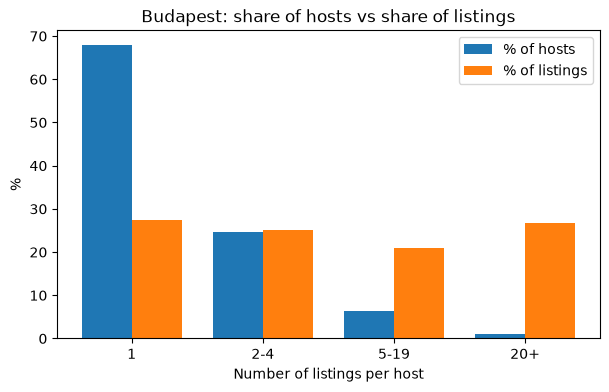

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(summary))
w = 0.38
ax.bar(x - w / 2, summary["hosts_%"], w, label="% of hosts")
ax.bar(x + w / 2, summary["listings_%"], w, label="% of listings")
ax.set_xticks(x)
ax.set_xticklabels(summary.index)
ax.set_xlabel("Number of listings per host")
ax.set_ylabel("%")
ax.set_title("Budapest: share of hosts vs share of listings")
ax.legend()
fig.savefig("../outputs/fig_hosts_vs_listings.png", dpi=150, bbox_inches="tight")
plt.show()

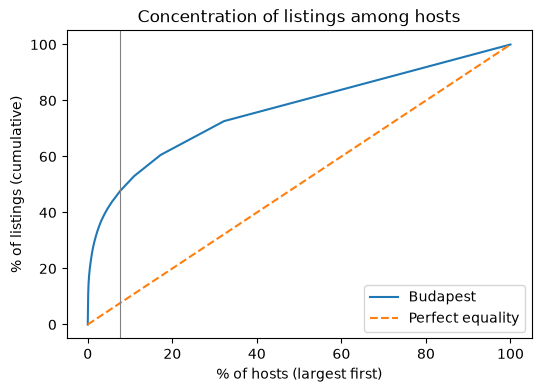

In [12]:
cum_hosts = np.arange(1, len(top) + 1) / len(top) * 100
cum_listings = top.cumsum().values / top.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.r_[0, cum_hosts], np.r_[0, cum_listings], label="Budapest")
ax.plot([0, 100], [0, 100], "--", label="Perfect equality")
ax.axvline(n5 / len(top) * 100, color="grey", lw=0.8)
ax.set_xlabel("% of hosts (largest first)")
ax.set_ylabel("% of listings (cumulative)")
ax.set_title("Concentration of listings among hosts")
ax.legend()
fig.savefig("../outputs/fig_pareto.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
counts = df["neighbourhood_cleansed"].value_counts().rename("n")
shares = pd.crosstab(df["neighbourhood_cleansed"], df["host_group_total"], normalize="index") * 100
shares["5+_%"] = shares["5-19"] + shares["20+"]

districts = pd.concat([counts, shares.round(1)], axis=1)
districts_big = districts[districts["n"] >= 100].sort_values("5+_%", ascending=False)
districts_big

,n,1,2-4,5-19,20+,5+_%
neighbourhood_cleansed,,,,,,
VIII. kerület,1869,21.7,21.8,20.5,35.9,56.4
VII. kerület,3468,21.7,22.7,24.1,31.5,55.6
V. kerület,1353,25.4,28.5,22.7,23.4,46.0
IX. kerület,860,28.8,26.3,22.0,22.9,44.9
VI. kerület,1214,27.4,29.7,22.9,19.9,42.8
XIII. kerület,812,36.1,24.0,12.4,27.5,39.9
XIV. kerület,176,36.4,27.3,18.8,17.6,36.4
I. kerület,418,41.4,24.2,19.9,14.6,34.4
XI. kerület,285,40.4,25.6,14.0,20.0,34.0


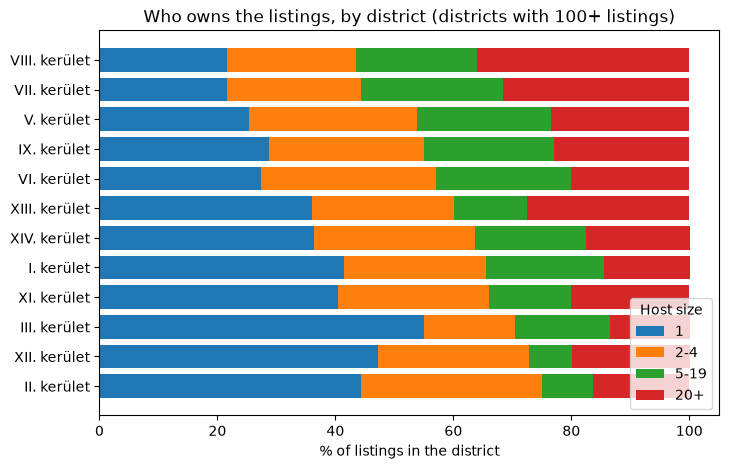

In [14]:
plot = districts_big.sort_values("5+_%")
fig, ax = plt.subplots(figsize=(8, 5))
left = np.zeros(len(plot))
for g in labels:
    ax.barh(plot.index, plot[g], left=left, label=g)
    left += plot[g].values
ax.set_xlabel("% of listings in the district")
ax.set_title("Who owns the listings, by district (districts with 100+ listings)")
ax.legend(title="Host size", loc="lower right")
fig.savefig("../outputs/fig_districts.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
df.groupby("center")["host_group_total"].apply(lambda s: s.isin(["5-19", "20+"]).mean() * 100).round(1)

center
False    43.7
True     50.9
Name: host_group_total, dtype: float64

## Stage 3. Ratings (H1, H3, H5)

### H1: rating spread vs number of reviews

In [51]:
rt = df[df["review_scores_rating"].notna()].copy()
rt["reviews_group"] = pd.cut(
    rt["number_of_reviews"],
    bins=[0, 4, 9, 29, 99, np.inf],
    labels=["1-4", "5-9", "10-29", "30-99", "100+"],
)

h1 = rt.groupby("reviews_group", observed=True)["review_scores_rating"].agg(
    n="size",
    median="median",
    p10=lambda s: s.quantile(0.10),
    p90=lambda s: s.quantile(0.90),
    std="std",
    share_5_0=lambda s: (s == 5).mean() * 100,
    share_4_7_plus=lambda s: (s >= 4.7).mean() * 100,
).round(2)
h1

,n,median,p10,p90,std,share_5_0,share_4_7_plus
reviews_group,,,,,,,
1-4,1198,5.00,3.50,5.00,0.81,55.26,59.02
5-9,773,4.78,4.00,5.00,0.40,31.44,56.53
10-29,1710,4.77,4.38,5.00,0.25,12.98,62.28
30-99,2949,4.81,4.52,4.96,0.18,3.59,73.01
100+,3795,4.84,4.62,4.96,0.14,0.84,82.11


In [17]:
r10 = rt.loc[rt["number_of_reviews"] >= 10, "review_scores_rating"]
print(f"10+ reviews: {len(r10)} listings; 80% of them lie between "
      f"{r10.quantile(.10):.2f} and {r10.quantile(.90):.2f}; median {r10.median():.2f}")

10+ reviews: 8454 listings; 80% of them lie between 4.53 and 4.96; median 4.82


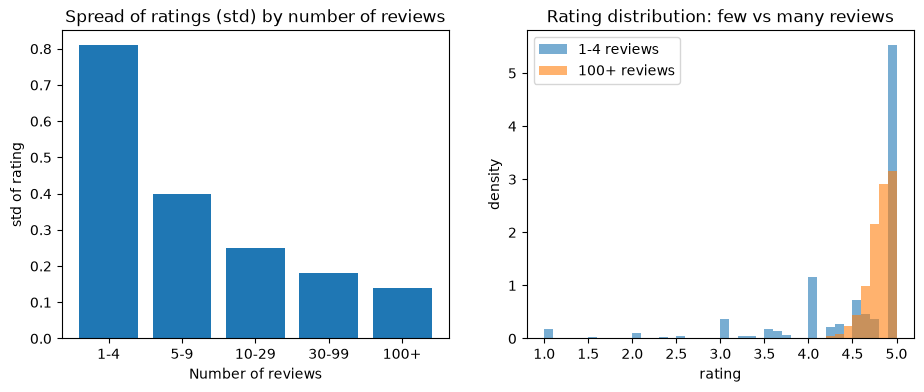

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(h1.index.astype(str), h1["std"])
axes[0].set_title("Spread of ratings (std) by number of reviews")
axes[0].set_xlabel("Number of reviews")
axes[0].set_ylabel("std of rating")

hist_bins = np.linspace(1, 5, 41)
for grp in ["1-4", "100+"]:
    axes[1].hist(rt.loc[rt["reviews_group"] == grp, "review_scores_rating"],
                 bins=hist_bins, density=True, alpha=0.6, label=f"{grp} reviews")
axes[1].set_title("Rating distribution: few vs many reviews")
axes[1].set_xlabel("rating")
axes[1].set_ylabel("density")
axes[1].legend()

fig.savefig("../outputs/fig_h1_rating_spread.png", dpi=150, bbox_inches="tight")
plt.show()

### H3: sub-scores

In [19]:
sub = ["review_scores_rating", "review_scores_accuracy", "review_scores_cleanliness",
       "review_scores_checkin", "review_scores_communication",
       "review_scores_location", "review_scores_value"]
x = df.loc[df["number_of_reviews"] >= 10, sub]

h3 = pd.DataFrame({
    "median": x.median(),
    "p10": x.quantile(0.10),
    "p90": x.quantile(0.90),
    "std": x.std(),
    "IQR": x.quantile(0.75) - x.quantile(0.25),
}).round(2)
h3["gap_to_5"] = (5 - h3["median"]).round(2)
h3.index = [i.replace("review_scores_", "") for i in h3.index]
h3.sort_values("std", ascending=False)

,median,p10,p90,std,IQR,gap_to_5
cleanliness,4.79,4.45,4.96,0.21,0.27,0.21
rating,4.82,4.53,4.96,0.18,0.22,0.18
checkin,4.89,4.67,4.98,0.16,0.15,0.11
value,4.82,4.58,4.93,0.16,0.18,0.18
accuracy,4.87,4.63,4.97,0.15,0.17,0.13
location,4.87,4.67,4.97,0.14,0.15,0.13
communication,4.91,4.71,4.99,0.13,0.13,0.09


### H5: rating and Superhost by host size

In [20]:
big_districts = main["neighbourhood_cleansed"].value_counts()
big_districts = big_districts[big_districts >= 100].index

for t in (main, rated):
    t["district_grp"] = t["neighbourhood_cleansed"].where(
        t["neighbourhood_cleansed"].isin(big_districts), "Other")

print(rated["district_grp"].nunique(), "district groups")

12 district groups


In [21]:
h5 = rated.groupby("host_group", observed=True).agg(
    n=("id", "size"),
    median_rating=("review_scores_rating", "median"),
    mean_rating=("review_scores_rating", "mean"),
    superhost_pct=("superhost", lambda s: s.mean() * 100),
).round(2)
h5

,n,median_rating,mean_rating,superhost_pct
host_group,,,,
1,2161,4.88,4.84,61.18
2-4,1841,4.86,4.82,64.64
5-19,1329,4.81,4.78,54.03
20+,1876,4.71,4.68,23.13


## Stage 4. Price (H6, H7, H2)

In [52]:
import statsmodels.formula.api as smf

def host_terms(model, scale=1):
    ci = model.conf_int()
    t = pd.DataFrame({"coef": model.params, "ci_low": ci[0], "ci_high": ci[1], "p": model.pvalues})
    t = t.filter(like="host_group", axis=0).copy()
    t[["coef", "ci_low", "ci_high"]] *= scale
    return t.round(3)

controls = "C(bedrooms_cap) + C(district_grp) + np.log(number_of_reviews)"

# rating (points on the 1-5 scale)
m_raw = smf.ols("review_scores_rating ~ C(host_group)", data=rated).fit(cov_type="HC3")
m_adj = smf.ols(f"review_scores_rating ~ C(host_group) + {controls}", data=rated).fit(cov_type="HC3")
print("Rating, raw:");      display(host_terms(m_raw))
print("Rating, adjusted:"); display(host_terms(m_adj))

# superhost status (percentage points)
s_raw = smf.ols("superhost ~ C(host_group)", data=rated).fit(cov_type="HC3")
s_adj = smf.ols(f"superhost ~ C(host_group) + {controls}", data=rated).fit(cov_type="HC3")
print("Superhost, raw (pp):");      display(host_terms(s_raw, scale=100))
print("Superhost, adjusted (pp):"); display(host_terms(s_adj, scale=100))

Rating, raw:


,coef,ci_low,ci_high,p
C(host_group)[T.2-4],-0.021,-0.031,-0.012,0.0
C(host_group)[T.5-19],-0.063,-0.074,-0.052,0.0
C(host_group)[T.20+],-0.166,-0.177,-0.156,0.0


Rating, adjusted:


,coef,ci_low,ci_high,p
C(host_group)[T.2-4],-0.018,-0.027,-0.009,0.0
C(host_group)[T.5-19],-0.049,-0.060,-0.038,0.0
C(host_group)[T.20+],-0.146,-0.157,-0.136,0.0


Superhost, raw (pp):


,coef,ci_low,ci_high,p
C(host_group)[T.2-4],3.463,0.463,6.463,0.024
C(host_group)[T.5-19],-7.150,-10.529,-3.771,0.000
C(host_group)[T.20+],-38.041,-40.847,-35.235,0.000


Superhost, adjusted (pp):


,coef,ci_low,ci_high,p
C(host_group)[T.2-4],3.148,0.273,6.022,0.032
C(host_group)[T.5-19],-4.914,-8.195,-1.633,0.003
C(host_group)[T.20+],-33.647,-36.454,-30.839,0.000


In [23]:
import statsmodels.formula.api as smf

def quote_group(m):
    return m if m in ("2026-09", "2026-10", "2026-11") else "later"

for t in (main, rated):
    t["quote_grp"] = t["quote_month"].map(quote_group)

rated["quote_grp"].value_counts()

quote_grp
2026-09    4052
2026-10    2607
later       298
2026-11     250
Name: count, dtype: int64

In [24]:
print(main.groupby("host_group", observed=True)["price_num"].agg(["median", "size"]).round(0))
print(rated.groupby("host_group", observed=True)["price_num"].agg(["median", "size"]).round(0))

             median  size
host_group               
1           35293.0  2570
2-4         34627.0  2207
5-19        34613.0  1708
20+         35766.0  2371
             median  size
host_group               
1           34302.0  2161
2-4         33421.0  1841
5-19        33406.0  1329
20+         34958.0  1876


In [25]:
cell = (main.groupby(["bedrooms_cap", "center", "host_group"], observed=True)["price_num"]
        .agg(median="median", n="size").reset_index())
cell.loc[cell["n"] < 30, "median"] = np.nan   # hide small cells

med = cell.pivot(index=["bedrooms_cap", "center"], columns="host_group", values="median").round(0)
cnt = cell.pivot(index=["bedrooms_cap", "center"], columns="host_group", values="n")
gap = (med.div(med["1"], axis=0) - 1).mul(100).round(1).drop(columns="1")

display(med); display(cnt); display(gap)

host_group                 1       2-4     5-19       20+
bedrooms_cap center                                      
0            False   28000.0   28882.0  28956.0   27944.0
             True    29057.0   27206.0  27257.0   28413.0
1            False   30634.0   30270.0  29274.0   30184.0
             True    33042.0   30728.0  29372.0   30980.0
2            False   42590.0   39776.0  42708.0   37462.0
             True    42421.0   43752.0  43622.0   46288.0
3            False   59903.0   58101.0  58703.0   50338.0
             True    63290.0   62887.0  56754.0   58901.0
4            False   93319.0  111914.0  75538.0  135447.0
             True    89942.0   85864.0  98396.0   68400.0

host_group             1  2-4  5-19  20+
bedrooms_cap center                     
0            False    77   66    39   80
             True     73  104    67   85
1            False   838  629   409  519
             True    647  614   519  788
2            False   372  247   144  237
             True    287  301   264  307
3            False   113   86    50  101
             True     91   92   119  108
4            False    38   34    39   85
             True     34   34    58   61

host_group            2-4  5-19   20+
bedrooms_cap center                  
0            False    3.2   3.4  -0.2
             True    -6.4  -6.2  -2.2
1            False   -1.2  -4.4  -1.5
             True    -7.0 -11.1  -6.2
2            False   -6.6   0.3 -12.0
             True     3.1   2.8   9.1
3            False   -3.0  -2.0 -16.0
             True    -0.6 -10.3  -6.9
4            False   19.9 -19.1  45.1
             True    -4.5   9.4 -24.0

In [26]:
import statsmodels.formula.api as smf

def quote_group(m):
    return m if m in ("2026-09", "2026-10", "2026-11") else "later"

for t in (main, rated):
    t["quote_grp"] = t["quote_month"].map(quote_group)

rated["quote_grp"].value_counts()

quote_grp
2026-09    4052
2026-10    2607
later       298
2026-11     250
Name: count, dtype: int64

### Median price by host group

In [53]:
cmp = pd.concat(
    {
        "main (all entire homes with a price)":
            main.groupby("host_group", observed=True)["price_num"].agg(median="median", n="size"),
        "rated (10+ reviews, with a rating)":
            rated.groupby("host_group", observed=True)["price_num"].agg(median="median", n="size"),
    },
    axis=1,
).round(0).astype(int)
cmp

main (all entire homes with a price)        \
                                         median     n   
host_group                                              
1                                         35293  2570   
2-4                                       34627  2207   
5-19                                      34613  1708   
20+                                       35766  2371   

           rated (10+ reviews, with a rating)        
                                       median     n  
host_group                                           
1                                       34302  2161  
2-4                                     33421  1841  
5-19                                    33406  1329  
20+                                     34958  1876

In [28]:
cell = (main.groupby(["bedrooms_cap", "center", "host_group"], observed=True)["price_num"]
        .agg(median="median", n="size").reset_index())
cell.loc[cell["n"] < 30, "median"] = np.nan   # hide small cells

med = cell.pivot(index=["bedrooms_cap", "center"], columns="host_group", values="median").round(0)
cnt = cell.pivot(index=["bedrooms_cap", "center"], columns="host_group", values="n")
gap = (med.div(med["1"], axis=0) - 1).mul(100).round(1).drop(columns="1")

display(med); display(cnt); display(gap)

host_group                 1       2-4     5-19       20+
bedrooms_cap center                                      
0            False   28000.0   28882.0  28956.0   27944.0
             True    29057.0   27206.0  27257.0   28413.0
1            False   30634.0   30270.0  29274.0   30184.0
             True    33042.0   30728.0  29372.0   30980.0
2            False   42590.0   39776.0  42708.0   37462.0
             True    42421.0   43752.0  43622.0   46288.0
3            False   59903.0   58101.0  58703.0   50338.0
             True    63290.0   62887.0  56754.0   58901.0
4            False   93319.0  111914.0  75538.0  135447.0
             True    89942.0   85864.0  98396.0   68400.0

host_group             1  2-4  5-19  20+
bedrooms_cap center                     
0            False    77   66    39   80
             True     73  104    67   85
1            False   838  629   409  519
             True    647  614   519  788
2            False   372  247   144  237
             True    287  301   264  307
3            False   113   86    50  101
             True     91   92   119  108
4            False    38   34    39   85
             True     34   34    58   61

host_group            2-4  5-19   20+
bedrooms_cap center                  
0            False    3.2   3.4  -0.2
             True    -6.4  -6.2  -2.2
1            False   -1.2  -4.4  -1.5
             True    -7.0 -11.1  -6.2
2            False   -6.6   0.3 -12.0
             True     3.1   2.8   9.1
3            False   -3.0  -2.0 -16.0
             True    -0.6 -10.3  -6.9
4            False   19.9 -19.1  45.1
             True    -4.5   9.4 -24.0

### Price gap by host size, step by step (H6)

In [29]:
steps = [
    ("1 host group", "C(host_group)"),
    ("2 + bedrooms", "C(host_group) + C(bedrooms_cap)"),
    ("3 + district", "C(host_group) + C(bedrooms_cap) + C(district_grp)"),
    ("4 + rating, superhost", "C(host_group) + C(bedrooms_cap) + C(district_grp) + review_scores_rating + superhost"),
    ("5 + quote month", "C(host_group) + C(bedrooms_cap) + C(district_grp) + review_scores_rating + superhost + C(quote_grp)"),
]

def fit(data, rhs, y="log_price"):
    return smf.ols(f"{y} ~ {rhs}", data=data).fit(cov_type="HC3")

def host_effects(data, step_list):
    rows = []
    for name, rhs in step_list:
        m = fit(data, rhs)
        ci = m.conf_int()
        for g in ["2-4", "5-19", "20+"]:
            k = f"C(host_group)[T.{g}]"
            rows.append({"model": name, "group": g, "n": int(m.nobs), "R2": round(m.rsquared, 3),
                         "pct": (np.exp(m.params[k]) - 1) * 100,
                         "lo": (np.exp(ci.loc[k, 0]) - 1) * 100,
                         "hi": (np.exp(ci.loc[k, 1]) - 1) * 100})
    return pd.DataFrame(rows)

def show(eff):
    eff = eff.copy()
    eff["text"] = eff.apply(lambda r: f"{r.pct:+.1f}% [{r.lo:+.1f}, {r.hi:+.1f}]", axis=1)
    tbl = eff.pivot(index="model", columns="group", values="text")[["2-4", "5-19", "20+"]]
    return tbl.join(eff.groupby("model")["R2"].first())

eff = host_effects(rated, steps)
show(eff)

,2-4,5-19,20+,R2
model,,,,
1 host group,"-3.0% [-6.0, +0.1]","-2.1% [-5.4, +1.3]","-0.6% [-3.5, +2.4]",0.001
2 + bedrooms,"-2.8% [-5.4, -0.2]","-5.5% [-8.1, -2.7]","-3.3% [-5.6, -0.8]",0.304
3 + district,"-3.3% [-5.8, -0.8]","-5.5% [-8.1, -2.7]","-2.2% [-4.6, +0.2]",0.327
"4 + rating, superhost","-2.4% [-4.9, +0.1]","-3.4% [-6.1, -0.6]","+3.2% [+0.3, +6.1]",0.346
5 + quote month,"-1.9% [-4.4, +0.6]","-2.7% [-5.4, +0.1]","+4.4% [+1.5, +7.3]",0.357


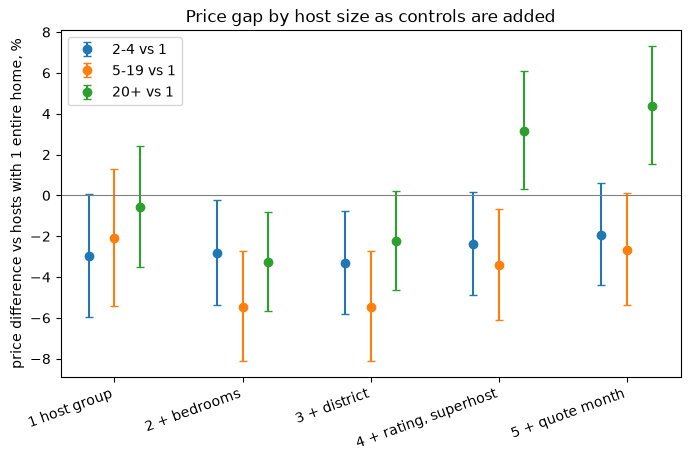

In [30]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, g in enumerate(["2-4", "5-19", "20+"]):
    s = eff[eff["group"] == g].reset_index(drop=True)
    xpos = np.arange(len(s)) + (i - 1) * 0.2
    ax.errorbar(xpos, s["pct"], yerr=[s["pct"] - s["lo"], s["hi"] - s["pct"]],
                fmt="o", capsize=3, label=f"{g} vs 1")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(range(len(steps)))
ax.set_xticklabels([n for n, _ in steps], rotation=20, ha="right")
ax.set_ylabel("price difference vs hosts with 1 entire home, %")
ax.set_title("Price gap by host size as controls are added")
ax.legend()
fig.savefig("../outputs/fig_h6_host_price_gap.png", dpi=150, bbox_inches="tight")
plt.show()

### What each factor explains (H7)

In [31]:
blocks = {
    "host group only": "C(host_group)",
    "bedrooms only": "C(bedrooms_cap)",
    "district only": "C(district_grp)",
    "rating + superhost only": "review_scores_rating + superhost",
    "quote month only": "C(quote_grp)",
    "bedrooms + district": "C(bedrooms_cap) + C(district_grp)",
    "full model without host group": "C(bedrooms_cap) + C(district_grp) + review_scores_rating + superhost + C(quote_grp)",
    "full model": steps[-1][1],
}
pd.Series({k: round(smf.ols(f"log_price ~ {v}", data=rated).fit().rsquared, 3) for k, v in blocks.items()})

host group only                  0.001
bedrooms only                    0.302
district only                    0.023
rating + superhost only          0.025
quote month only                 0.016
bedrooms + district              0.326
full model without host group    0.355
full model                       0.357
dtype: float64

### Rating and Superhost vs price (H2)

In [32]:
m5 = fit(rated, steps[-1][1])
p10, p90 = rated["review_scores_rating"].quantile([0.10, 0.90])
span = p90 - p10
pct = lambda v: (np.exp(v) - 1) * 100

b = m5.params["review_scores_rating"]
lo, hi = m5.conf_int().loc["review_scores_rating"]
print(f"Rating p10 ({p10:.2f}) -> p90 ({p90:.2f}): {pct(b*span):+.1f}% price [{pct(lo*span):+.1f}, {pct(hi*span):+.1f}]")

bs = m5.params["superhost"]
los, his = m5.conf_int().loc["superhost"]
print(f"Superhost: {pct(bs):+.1f}% [{pct(los):+.1f}, {pct(his):+.1f}]")

Rating p10 (4.54) -> p90 (4.96): +21.6% price [+18.2, +25.2]
Superhost: -4.1% [-6.2, -1.9]


### Central vs non-central districts (H6)

In [33]:
for name, sub in [("central (V, VI, VII)", rated[rated["center"]]),
                  ("non-central", rated[~rated["center"]])]:
    e = host_effects(sub, [(name, steps[-1][1])])
    print(name, "n =", e["n"].iloc[0], "R2 =", e["R2"].iloc[0])
    display(show(e)[["2-4", "5-19", "20+"]])

central (V, VI, VII) n = 3826 R2 = 0.381


,2-4,5-19,20+
model,,,
"central (V, VI, VII)","-3.7% [-7.1, -0.1]","-3.8% [-7.5, +0.0]","+5.8% [+1.9, +10.0]"


non-central n = 3381 R2 = 0.339


,2-4,5-19,20+
model,,,
non-central,"+0.2% [-3.3, +3.9]","-1.4% [-5.5, +2.8]","+2.7% [-1.4, +7.0]"


## Stage 5. Demand (H8, H9, H2)

In [34]:
import statsmodels.api as sm

for t in (main, rated):
    t["log_reviews_ltm"] = np.log1p(t["number_of_reviews_ltm"])
    t["occ"] = t["estimated_occupancy_l365d"]

### Demand by host group

In [35]:
print("Sample: main (entire homes with a price)")
g = main.groupby("host_group", observed=True)
desc = pd.DataFrame({
    "n": g.size(),
    "median_reviews_ltm": g["number_of_reviews_ltm"].median(),
    "mean_reviews_ltm": g["number_of_reviews_ltm"].mean().round(1),
    "zero_reviews_%": g["number_of_reviews_ltm"].apply(lambda s: (s == 0).mean() * 100).round(1),
    "median_occupancy": g["occ"].median(),
    "at_cap_255_%": g["occ"].apply(lambda s: (s >= 255).mean() * 100).round(1),
})
desc

Sample: main (entire homes with a price)


,n,median_reviews_ltm,mean_reviews_ltm,zero_reviews_%,median_occupancy,at_cap_255_%
host_group,,,,,,
1,2570,19.0,24.2,11.4,114.0,21.1
2-4,2207,19.0,25.4,10.2,120.0,24.0
5-19,1708,18.0,26.1,9.5,114.0,27.2
20+,2371,17.0,23.1,8.0,102.0,21.0


### Demand gap by host size (H8)

In [36]:
steps_d = [
    ("1 host group", "C(host_group)"),
    ("2 + bedrooms", "C(host_group) + C(bedrooms_cap)"),
    ("3 + district", "C(host_group) + C(bedrooms_cap) + C(district_grp)"),
    ("4 + price, quote month", "C(host_group) + C(bedrooms_cap) + C(district_grp) + log_price + C(quote_grp)"),
    ("5 + minimum nights", "C(host_group) + C(bedrooms_cap) + C(district_grp) + log_price + C(quote_grp) + minimum_nights"),
]

def fit_y(data, rhs, y):
    return smf.ols(f"{y} ~ {rhs}", data=data).fit(cov_type="HC3")

def host_effects_y(data, step_list, y):
    rows = []
    for name, rhs in step_list:
        m = fit_y(data, rhs, y)
        ci = m.conf_int()
        for g_ in ["2-4", "5-19", "20+"]:
            k = f"C(host_group)[T.{g_}]"
            rows.append({"model": name, "group": g_, "n": int(m.nobs), "R2": round(m.rsquared, 3),
                         "pct": (np.exp(m.params[k]) - 1) * 100,
                         "lo": (np.exp(ci.loc[k, 0]) - 1) * 100,
                         "hi": (np.exp(ci.loc[k, 1]) - 1) * 100})
    return pd.DataFrame(rows)

print("Sample: main | outcome: log(1 + reviews in last 12 months) | % difference vs hosts with 1 entire home")
eff_d = host_effects_y(main, steps_d, "log_reviews_ltm")
show(eff_d)

Sample: main | outcome: log(1 + reviews in last 12 months) | % difference vs hosts with 1 entire home


,2-4,5-19,20+,R2
model,,,,
1 host group,"+3.4% [-4.3, +11.6]","+3.4% [-4.9, +12.4]","-0.9% [-7.9, +6.6]",0.000
2 + bedrooms,"+3.1% [-4.5, +11.3]","+4.5% [-3.8, +13.6]","+0.1% [-6.9, +7.7]",0.006
3 + district,"+1.4% [-6.0, +9.4]","-0.0% [-8.0, +8.6]","-5.8% [-12.4, +1.4]",0.030
"4 + price, quote month","-2.8% [-9.4, +4.3]","-8.0% [-14.8, -0.6]","-12.5% [-18.4, -6.2]",0.139
5 + minimum nights,"-3.0% [-9.5, +4.0]","-10.3% [-17.0, -3.1]","-16.3% [-21.9, -10.3]",0.153


### Price and demand (H9)

In [37]:
mult = lambda v: (1.10 ** v - 1) * 100   # effect of a 10% higher price

for name, rhs in steps_d[3:]:
    m = fit_y(main, rhs, "log_reviews_ltm")
    lo, hi = m.conf_int().loc["log_price"]
    print(f"{name}: +10% price -> {mult(m.params['log_price']):+.1f}% reviews [{mult(lo):+.1f}, {mult(hi):+.1f}]")
print(f"Each extra minimum night: {(np.exp(m.params['minimum_nights']) - 1) * 100:+.1f}% reviews")

4 + price, quote month: +10% price -> -7.3% reviews [-7.8, -6.8]
5 + minimum nights: +10% price -> -7.6% reviews [-8.1, -7.0]
Each extra minimum night: -10.0% reviews


### Rating and Superhost vs demand (H2)

In [38]:
full_nr = steps_d[-1][1]
full_r = full_nr + " + review_scores_rating + superhost"
pct = lambda v: (np.exp(v) - 1) * 100

samples = {
    "rated (10+ reviews, with a rating)": rated,
    "main restricted to listings with a rating": main[main["review_scores_rating"].notna()],
}
for label, data in samples.items():
    a = fit_y(data, full_nr, "log_reviews_ltm")
    b = fit_y(data, full_r, "log_reviews_ltm")
    ci = b.conf_int()
    p10, p90 = data["review_scores_rating"].quantile([0.10, 0.90])
    span = p90 - p10
    k20 = "C(host_group)[T.20+]"
    print(label, "| n =", int(b.nobs), "| R2 without / with rating+superhost:", round(a.rsquared, 3), "/", round(b.rsquared, 3))
    print(f"   rating {p10:.2f} -> {p90:.2f}: {pct(b.params['review_scores_rating'] * span):+.1f}% reviews "
          f"[{pct(ci.loc['review_scores_rating', 0] * span):+.1f}, {pct(ci.loc['review_scores_rating', 1] * span):+.1f}]")
    print(f"   superhost: {pct(b.params['superhost']):+.1f}% [{pct(ci.loc['superhost', 0]):+.1f}, {pct(ci.loc['superhost', 1]):+.1f}]")
    print(f"   host 20+ vs 1: {pct(a.params[k20]):+.1f}% without rating/superhost, {pct(b.params[k20]):+.1f}% with")

rated (10+ reviews, with a rating) | n = 7207 | R2 without / with rating+superhost: 0.142 / 0.256
   rating 4.54 -> 4.96: +45.2% reviews [+35.6, +55.4]
   superhost: +79.5% [+69.8, +89.8]
   host 20+ vs 1: -6.4% without rating/superhost, +34.6% with
main restricted to listings with a rating | n = 8502 | R2 without / with rating+superhost: 0.137 / 0.274
   rating 4.50 -> 5.00: +37.6% reviews [+31.2, +44.3]
   superhost: +123.3% [+111.7, +135.6]
   host 20+ vs 1: -17.2% without rating/superhost, +20.3% with


### Checks: Poisson and occupancy

In [39]:
pm = smf.glm("number_of_reviews_ltm ~ " + steps_d[-1][1], data=main,
             family=sm.families.Poisson()).fit(cov_type="HC1")
ci = pm.conf_int()
print("Poisson on review counts (main):")
for g_ in ["2-4", "5-19", "20+"]:
    k = f"C(host_group)[T.{g_}]"
    print(f"   {g_} vs 1: {pct(pm.params[k]):+.1f}% [{pct(ci.loc[k, 0]):+.1f}, {pct(ci.loc[k, 1]):+.1f}]")
print(f"   +10% price: {mult(pm.params['log_price']):+.1f}% [{mult(ci.loc['log_price', 0]):+.1f}, {mult(ci.loc['log_price', 1]):+.1f}]")

for label, data in [("estimated occupancy, all", main),
                    ("estimated occupancy, without the 255 cap", main[main["occ"] < 255])]:
    m = smf.ols("occ ~ " + steps_d[-1][1], data=data).fit(cov_type="HC3")
    ci = m.conf_int()
    print(f"{label} (n = {int(m.nobs)}, R2 = {m.rsquared:.3f}):")
    for g_ in ["2-4", "5-19", "20+"]:
        k = f"C(host_group)[T.{g_}]"
        print(f"   {g_} vs 1: {m.params[k]:+.1f} nights [{ci.loc[k, 0]:+.1f}, {ci.loc[k, 1]:+.1f}]")

Poisson on review counts (main):
   2-4 vs 1: -1.6% [-6.3, +3.4]
   5-19 vs 1: -5.9% [-10.9, -0.7]
   20+ vs 1: -18.7% [-22.9, -14.3]
   +10% price: -5.5% [-5.9, -5.0]
estimated occupancy, all (n = 8856, R2 = 0.121):
   2-4 vs 1: -1.7 nights [-6.9, +3.4]
   5-19 vs 1: -6.2 nights [-12.0, -0.5]
   20+ vs 1: -14.8 nights [-20.1, -9.5]
estimated occupancy, without the 255 cap (n = 6821, R2 = 0.090):
   2-4 vs 1: -4.5 nights [-9.3, +0.3]
   5-19 vs 1: -12.8 nights [-18.1, -7.5]
   20+ vs 1: -12.1 nights [-17.0, -7.2]


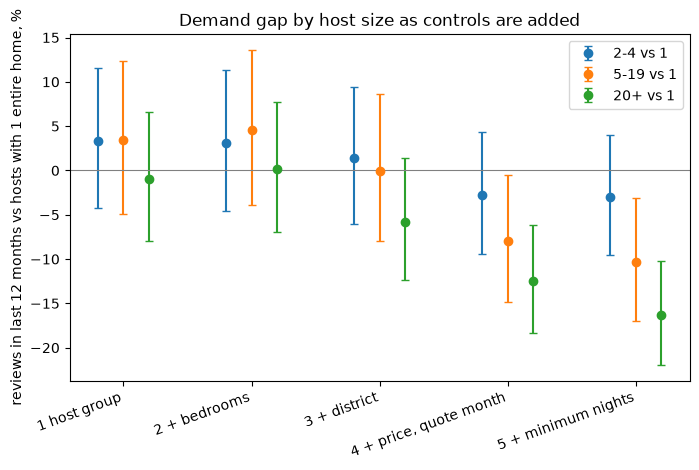

In [40]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, g_ in enumerate(["2-4", "5-19", "20+"]):
    s = eff_d[eff_d["group"] == g_].reset_index(drop=True)
    xpos = np.arange(len(s)) + (i - 1) * 0.2
    ax.errorbar(xpos, s["pct"], yerr=[s["pct"] - s["lo"], s["hi"] - s["pct"]],
                fmt="o", capsize=3, label=f"{g_} vs 1")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(range(len(steps_d)))
ax.set_xticklabels([n for n, _ in steps_d], rotation=20, ha="right")
ax.set_ylabel("reviews in last 12 months vs hosts with 1 entire home, %")
ax.set_title("Demand gap by host size as controls are added")
ax.legend()
fig.savefig("../outputs/fig_h8_host_demand_gap.png", dpi=150, bbox_inches="tight")
plt.show()

### First look: listings without reviews (B1)

In [41]:
main["ltm_status"] = np.where(main["number_of_reviews"] == 0, "never reviewed",
                     np.where(main["number_of_reviews_ltm"] == 0, "dormant (reviewed before)", "active"))
seg_median = main.groupby(["bedrooms_cap", "district_grp"])["price_num"].transform("median")
main["rel_price"] = main["price_num"] / seg_median   # price vs similar listings (same bedrooms + district)

b1 = main.groupby("ltm_status").agg(
    n=("id", "size"),
    price_median=("price_num", "median"),
    rel_price_median=("rel_price", "median"),
    superhost_pct=("superhost", lambda s: s.mean() * 100),
    prev_scrape_pct=("prev_scrape", lambda s: s.mean() * 100),
).round(2)
display(b1)
display((main.groupby("ltm_status")["host_group"].value_counts(normalize=True).unstack() * 100).round(1))

,n,price_median,rel_price_median,superhost_pct,prev_scrape_pct
ltm_status,,,,,
active,7984,34353.00,0.99,48.47,2.63
dormant (reviewed before),518,45093.50,1.29,11.78,4.63
never reviewed,354,51057.75,1.25,13.28,2.54


host_group,1,2-4,5-19,20+
ltm_status,,,,
active,28.5,24.8,19.4,27.3
dormant (reviewed before),33.6,28.2,19.1,19.1
never reviewed,33.9,22.6,18.1,25.4


### Superhost deep-dive

In [42]:
rb = pd.cut(rated["review_scores_rating"], [0, 4.5, 4.7, 4.8, 4.9, 5.01],
            labels=["<=4.5", "4.5-4.7", "4.7-4.8", "4.8-4.9", "4.9-5.0"])
print("Sample: rated | share of superhosts by listing rating")
display(rated.groupby(rb, observed=True).agg(
    n=("id", "size"), superhost_pct=("superhost", lambda s: round(s.mean() * 100, 1))))

lb = pd.cut(main["number_of_reviews_ltm"], [-1, 0, 4, 9, 19, 39, 1000],
            labels=["0", "1-4", "5-9", "10-19", "20-39", "40+"])
print("Sample: main | share of superhosts by reviews in the last 12 months")
display(main.groupby(lb, observed=True).agg(
    n=("id", "size"), superhost_pct=("superhost", lambda s: round(s.mean() * 100, 1))))

Sample: rated | share of superhosts by listing rating


,n,superhost_pct
review_scores_rating,,
<=4.5,599,4.5
4.5-4.7,1269,15.6
4.7-4.8,1360,39.3
4.8-4.9,2020,68.8
4.9-5.0,1959,77.3


Sample: main | share of superhosts by reviews in the last 12 months


,n,superhost_pct
number_of_reviews_ltm,,
0,872,12.4
1-4,1429,22.0
5-9,925,33.2
10-19,1346,48.5
20-39,2016,54.7
40+,2268,65.9


In [43]:
specs = [
    ("A superhost only", "superhost"),
    ("B + bedrooms, district, quote month", "superhost + C(bedrooms_cap) + C(district_grp) + C(quote_grp)"),
    ("C + host group", "superhost + C(bedrooms_cap) + C(district_grp) + C(quote_grp) + C(host_group)"),
    ("D + rating", "superhost + C(bedrooms_cap) + C(district_grp) + C(quote_grp) + C(host_group) + review_scores_rating"),
]
rows = []
for name, rhs in specs:
    m = fit_y(rated, rhs, "log_price")
    lo, hi = m.conf_int().loc["superhost"]
    rows.append({"model": name, "n": int(m.nobs),
                 "superhost_effect": f"{pct(m.params['superhost']):+.1f}% [{pct(lo):+.1f}, {pct(hi):+.1f}]"})
print("Sample: rated | outcome: log price")
display(pd.DataFrame(rows))

Sample: rated | outcome: log price


,model,n,superhost_effect
0,A superhost only,7207,"-1.2% [-3.4, +1.1]"
1,"B + bedrooms, district, quote month",7207,"+2.5% [+0.6, +4.4]"
2,C + host group,7207,"+3.0% [+0.9, +5.1]"
3,D + rating,7207,"-4.1% [-6.2, -1.9]"


In [44]:
rows = []
for g_ in ["1", "2-4", "5-19", "20+"]:
    s = rated[rated["host_group"] == g_]
    m = fit_y(s, "superhost + C(bedrooms_cap) + C(district_grp) + C(quote_grp) + review_scores_rating", "log_price")
    lo, hi = m.conf_int().loc["superhost"]
    rows.append({"host_group": g_, "n": int(m.nobs),
                 "superhost_share_%": round(s["superhost"].mean() * 100),
                 "superhost_effect": f"{pct(m.params['superhost']):+.1f}% [{pct(lo):+.1f}, {pct(hi):+.1f}]"})
display(pd.DataFrame(rows))

,host_group,n,superhost_share_%,superhost_effect
0,1,2161,61,"-13.4% [-17.3, -9.3]"
1,2-4,1841,65,"-2.0% [-6.2, +2.4]"
2,5-19,1329,54,"+0.0% [-4.7, +5.0]"
3,20+,1876,23,"+3.8% [-0.6, +8.4]"


## Stage 6. Robustness

In [45]:
df["quote_grp"] = df["quote_month"].map(quote_group)
df["district_grp"] = df["neighbourhood_cleansed"].where(df["neighbourhood_cleansed"].isin(big_districts), "Other")
df["log_reviews_ltm"] = np.log1p(df["number_of_reviews_ltm"])
df["occ"] = df["estimated_occupancy_l365d"]

### Sample builder

In [46]:
def build_samples(data, rooms=("Entire home/apt",), price_cut=0.99, drop_prev=False,
                  group_col="host_group", rated_rule="10+"):
    d = data[data["room_type"].isin(rooms)]
    if drop_prev:
        d = d[d["prev_scrape"] == 0]
    d = d[d["price_num"].notna() & (d["minimum_nights"] < 28)]
    if price_cut is not None:
        d = d[d["price_num"] <= d["price_num"].quantile(price_cut)]
    d = d.copy()
    d["host_group"] = d[group_col]
    d = d[d["host_group"].notna()].copy()
    has_rating = d["review_scores_rating"].notna()
    if rated_rule == "10+":
        r = d[has_rating & (d["number_of_reviews"] >= 10)]
    elif rated_rule == "any":
        r = d[has_rating]
    else:  # "4.7+"
        r = d[has_rating & (d["number_of_reviews"] >= 10) & (d["review_scores_rating"] >= 4.7)]
    return d, r.copy()

main_b, rated_b = build_samples(df)
print("baseline check:", len(main_b), len(rated_b))

baseline check: 8856 7207


### Robustness table

In [47]:
def term_effect(m, term, how="pct", span=1.0):
    b = m.params[term]
    lo, hi = m.conf_int().loc[term]
    if how == "pct":
        f = lambda v: (np.exp(v * span) - 1) * 100
    elif how == "pp":
        f = lambda v: v * 100
    else:
        f = lambda v: v
    return f(b), f(lo), f(hi)

def run_metrics(main_v, rated_v, extra=""):
    res = {}
    T20, T519 = "C(host_group)[T.20+]", "C(host_group)[T.5-19]"
    rhs3 = "C(host_group) + C(bedrooms_cap) + C(district_grp)" + extra
    full = rhs3 + " + review_scores_rating + superhost + C(quote_grp)"
    m = fit_y(rated_v, rhs3, "log_price")
    res["M1 price: 20+ vs 1 (size, district), %"] = term_effect(m, T20)
    res["M1b price: 5-19 vs 1 (size, district), %"] = term_effect(m, T519)
    m = fit_y(rated_v, full, "log_price")
    res["M2 price: 20+ vs 1 (full model), %"] = term_effect(m, T20)
    p10, p90 = rated_v["review_scores_rating"].quantile([0.10, 0.90])
    res["M3 price: rating p10->p90, %"] = term_effect(m, "review_scores_rating", span=p90 - p10)
    m = fit_y(main_v, rhs3, "log_reviews_ltm")
    res["M4 demand: 20+ vs 1 (size, district), %"] = term_effect(m, T20)
    m = fit_y(main_v, rhs3 + " + log_price + C(quote_grp) + minimum_nights", "log_reviews_ltm")
    res["M5 demand: 20+ vs 1 (with price), %"] = term_effect(m, T20)
    res["M5b demand: 5-19 vs 1 (with price), %"] = term_effect(m, T519)
    res["M6 demand: +10% price, %"] = term_effect(m, "log_price", span=np.log(1.10))
    ctrl = rhs3 + " + np.log(number_of_reviews)"
    m = fit_y(rated_v, ctrl, "review_scores_rating")
    res["M7 rating: 20+ vs 1, points"] = term_effect(m, T20, how="points")
    m = fit_y(rated_v, ctrl, "superhost")
    res["M8 superhost: 20+ vs 1, pp"] = term_effect(m, T20, how="pp")
    return res

variants = {
    "V0": ("baseline", dict()),
    "V1": ("no previous-scrape listings", dict(drop_prev=True)),
    "V2": ("host group by total count", dict(group_col="host_group_total")),
    "V3": ("rating sample: any number of reviews", dict(rated_rule="any")),
    "V4": ("rating sample: only rating 4.7+", dict(rated_rule="4.7+")),
    "V5": ("no price outlier cut", dict(price_cut=None)),
    "V6": ("price cut at 95th percentile", dict(price_cut=0.95)),
    "V7": ("entire homes + private rooms", dict(rooms=("Entire home/apt", "Private room"),
                                                group_col="host_group_total", extra=" + C(room_type)")),
}

allres, sizes = {}, {}
for key, (label, kw) in variants.items():
    kw = dict(kw)
    extra = kw.pop("extra", "")
    mv, rv = build_samples(df, **kw)
    sizes[key] = (len(mv), len(rv))
    allres[key] = run_metrics(mv, rv, extra)

display(pd.DataFrame({k: {"description": variants[k][0], "n_main": sizes[k][0], "n_rated": sizes[k][1]}
                      for k in variants}).T)

names = list(allres["V0"].keys())
def fmt(mn, e):
    est, lo, hi = e
    txt = f"{est:+.3f}" if "points" in mn else f"{est:+.1f}"
    return txt + ("*" if (lo > 0 or hi < 0) else "")

tab = pd.DataFrame({k: {mn: fmt(mn, allres[k][mn]) for mn in names} for k in variants})
tab["same sign in all?"] = ["yes" if all(np.sign(allres[k][mn][0]) == np.sign(allres["V0"][mn][0]) for k in variants)
                            else "no" for mn in names]
tab["significant in"] = [f"{sum(1 for k in variants if (allres[k][mn][1] > 0 or allres[k][mn][2] < 0))} of {len(variants)}"
                         for mn in names]
display(tab)

,description,n_main,n_rated
V0,baseline,8856,7207
V1,no previous-scrape listings,8613,7018
V2,host group by total count,8856,7207
V3,rating sample: any number of reviews,8856,8502
V4,rating sample: only rating 4.7+,8856,5438
V5,no price outlier cut,8946,7245
V6,price cut at 95th percentile,8498,7010
V7,entire homes + private rooms,9736,7529


,V0,V1,V2,V3,V4,V5,V6,V7,same sign in all?,significant in
"M1 price: 20+ vs 1 (size, district), %",-2.2,-1.6,-2.3,-3.4*,+1.5,-2.8*,+0.2,-1.8,no,2 of 8
"M1b price: 5-19 vs 1 (size, district), %",-5.5*,-5.0*,-5.5*,-5.0*,-3.9*,-4.3*,-3.7*,-5.3*,yes,8 of 8
"M2 price: 20+ vs 1 (full model), %",+4.4*,+4.9*,+4.4*,-0.9,+6.2*,+3.5*,+7.0*,+4.4*,no,7 of 8
"M3 price: rating p10->p90, %",+21.6*,+21.7*,+21.6*,+8.0*,+28.2*,+20.2*,+20.2*,+21.4*,yes,8 of 8
"M4 demand: 20+ vs 1 (size, district), %",-5.8,-7.0,-7.3*,-5.8,-5.8,-4.5,-8.0*,-9.8*,yes,3 of 8
"M5 demand: 20+ vs 1 (with price), %",-16.3*,-16.3*,-17.8*,-16.3*,-16.3*,-15.7*,-16.5*,-19.7*,yes,8 of 8
"M5b demand: 5-19 vs 1 (with price), %",-10.3*,-11.1*,-12.8*,-10.3*,-10.3*,-9.2*,-11.4*,-11.3*,yes,8 of 8
"M6 demand: +10% price, %",-7.6*,-7.7*,-7.6*,-7.6*,-7.6*,-6.5*,-7.6*,-8.0*,yes,8 of 8
"M7 rating: 20+ vs 1, points",-0.146*,-0.147*,-0.147*,-0.155*,-0.060*,-0.146*,-0.147*,-0.145*,yes,8 of 8
"M8 superhost: 20+ vs 1, pp",-33.6*,-33.7*,-33.9*,-27.0*,-27.6*,-33.5*,-34.1*,-33.3*,yes,8 of 8


### Which factor explains price in each variant

In [48]:
rows = []
for key, (label, kw) in variants.items():
    kw = dict(kw)
    extra = kw.pop("extra", "")
    mv, rv = build_samples(df, **kw)
    rows.append(pd.Series(
        {name: round(smf.ols(f"log_price ~ {rhs}{extra}", data=rv).fit().rsquared, 3)
         for name, rhs in [("bedrooms", "C(bedrooms_cap)"), ("district", "C(district_grp)"), ("host group", "C(host_group)")]},
        name=key))
display(pd.DataFrame(rows))

,bedrooms,district,host group
V0,0.302,0.023,0.001
V1,0.306,0.024,0.001
V2,0.302,0.023,0.001
V3,0.298,0.024,0.000
V4,0.315,0.026,0.001
V5,0.264,0.033,0.000
V6,0.302,0.024,0.001
V7,0.316,0.057,0.034


### Occupancy as outcome

In [49]:
rhs3 = "C(host_group) + C(bedrooms_cap) + C(district_grp)"
rhs5 = rhs3 + " + log_price + C(quote_grp) + minimum_nights"
for label, data in [("all", main_b), ("without the 255 cap", main_b[main_b["occ"] < 255])]:
    d_ = data.assign(log_occ=np.log1p(data["occ"]))
    m3 = fit_y(d_, rhs3, "log_occ")
    m5 = fit_y(d_, rhs5, "log_occ")
    e3 = term_effect(m3, "C(host_group)[T.20+]")
    e5 = term_effect(m5, "C(host_group)[T.20+]")
    e6 = term_effect(m5, "log_price", span=np.log(1.10))
    print(f"Occupancy, {label} (n = {int(m5.nobs)})")
    print(f"   20+ vs 1 (size, district): {e3[0]:+.1f}% [{e3[1]:+.1f}, {e3[2]:+.1f}]")
    print(f"   20+ vs 1 (with price):     {e5[0]:+.1f}% [{e5[1]:+.1f}, {e5[2]:+.1f}]")
    print(f"   +10% price:                {e6[0]:+.1f}% [{e6[1]:+.1f}, {e6[2]:+.1f}]")

Occupancy, all (n = 8856)
   20+ vs 1 (size, district): -1.1% [-9.9, +8.7]
   20+ vs 1 (with price):     -12.2% [-19.7, -4.0]
   +10% price:                -9.9% [-10.6, -9.1]
Occupancy, without the 255 cap (n = 6821)
   20+ vs 1 (size, district): +3.4% [-7.0, +15.1]
   20+ vs 1 (with price):     -11.1% [-19.7, -1.5]
   +10% price:                -9.0% [-9.8, -8.2]


## Stage 7. Export for Tableau

In [50]:
out = Path("..") / "outputs" / "tableau"
out.mkdir(parents=True, exist_ok=True)

# 1. Ratings by number of reviews (H1)
h1.reset_index().to_csv(out / "01_ratings_by_reviews.csv", index=False)

# 2. Hosts vs listings by host size (H4)
(summary.reset_index()
        .rename(columns={"hosts_%": "hosts_pct", "listings_%": "listings_pct"})
        .to_csv(out / "02_hosts_concentration.csv", index=False))

# 3. Who owns the listings, by district (long format for stacked bars)
(districts_big[["n", "1", "2-4", "5-19", "20+"]]
    .reset_index()
    .melt(id_vars=["neighbourhood_cleansed", "n"], var_name="host_group", value_name="share_pct")
    .to_csv(out / "03_districts_host_structure.csv", index=False))

# 4. How much each block explains of price (H7)
(pd.Series({k: round(smf.ols(f"log_price ~ {v}", data=rated).fit().rsquared, 3) for k, v in blocks.items()})
   .rename("R2").rename_axis("block").reset_index()
   .to_csv(out / "04_r2_by_block.csv", index=False))

# 5. Host-size gaps in price and demand across models (H6, H8)
(pd.concat([eff.assign(outcome="price"), eff_d.assign(outcome="demand (reviews, last 12 months)")])
   .to_csv(out / "05_host_gaps_by_model.csv", index=False))

# 6. Listing-level sample for a scatter plot (no host or listing identifiers)
cols = ["neighbourhood_cleansed", "host_group", "bedrooms_cap", "price_num",
        "number_of_reviews_ltm", "review_scores_rating", "superhost", "number_of_reviews"]
main[cols].to_csv(out / "06_listings_sample.csv", index=False)

for f in sorted(out.glob("*.csv")):
    print(f.name, pd.read_csv(f).shape)

01_ratings_by_reviews.csv (5, 8)
02_hosts_concentration.csv (4, 5)
03_districts_host_structure.csv (48, 4)
04_r2_by_block.csv (8, 2)
05_host_gaps_by_model.csv (30, 8)
06_listings_sample.csv (8856, 8)
